# Peer structure in the expanded 200-stock basket

October 28, 2026. [Full findings](experiments/equity_expanded_structure/README.md), [fixed specification](experiments/equity_expanded_structure/specification.json), [source](experiments/equity_expanded_structure.py), [data](../market_data/datasets/equity_daily_expanded_2016_2026-10-27/README.md).

**Result:** past-formed peer groups retain future co-movement, but fixed-K H0/single linkage remains dominated by one giant component. Average linkage has stronger future correlation separation at every declared cut/lookback, and nearly all stable small H0 branches also occur under average linkage. At matched K=11, average linkage also exceeds the broad snapshot-sector gap.

This is a structural comparison, **not a new trading or reversal backtest**. No P&L or fees are calculated. The current-survivor universe, current sector labels, and already examined dates remain exploratory. The notebook loads audited results rather than rerunning or choosing settings.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cwd = Path.cwd()
candidates = [cwd, cwd / "TDA_Research", cwd / "Senior-Fall" / "TDA_Research", *cwd.parents]
project = next(p for p in candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
out = root / "experiments" / "equity_expanded_structure"
summary = pd.read_csv(out / "cut_summary.csv")
paired = pd.read_csv(out / "paired_method_differences.csv")
sector = pd.read_csv(out / "sector_summary.csv")
anchors = pd.read_csv(out / "anchors.csv")
counts = pd.read_csv(out / "stable_branch_counts.csv")
overlap = pd.read_csv(out / "branch_overlap.csv")
catalogue = pd.read_csv(out / "named_local_branch_catalogue.csv")
result = json.loads((out / "summary.json").read_text())
audit = json.loads((out / "independent_audit.json").read_text())
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Nonoverlapping target blocks:", result["anchors_by_period"])
print("Past-eligible stock range:", result["eligible_stock_range"])
print("Admission: 272 complete prior returns; same names for both lookbacks and sector baseline")
print("Declared windows:", result["configuration"]["windows"], "| cuts:", result["configuration"]["scored_group_counts"])

Nonoverlapping target blocks: {'development': 86, 'later': 35}
Past-eligible stock range: [182, 200]
Admission: 272 complete prior returns; same names for both lookbacks and sector baseline
Declared windows: [120, 252] | cuts: [6, 11, 20, 40]


## 1. The global H0 cut still chains most stocks together

At eleven groups, later 252-session H0 puts about **186 of 199 stocks** in one component; average linkage's largest group averages **78**. Even forty H0 groups leave about **144 stocks** together and about **30 singletons**.

Single linkage joins groups when any connecting pair is close. Repeated local connections can make a giant component whose members are not all mutually close. Average linkage evaluates average cross-group distance and is less imbalanced here, although it does not promise equally sized groups.

All K=1..N balance measurements are saved. Future scores are evaluated only at the four declared cuts, avoiding an outcome-based search across 200 possible choices.

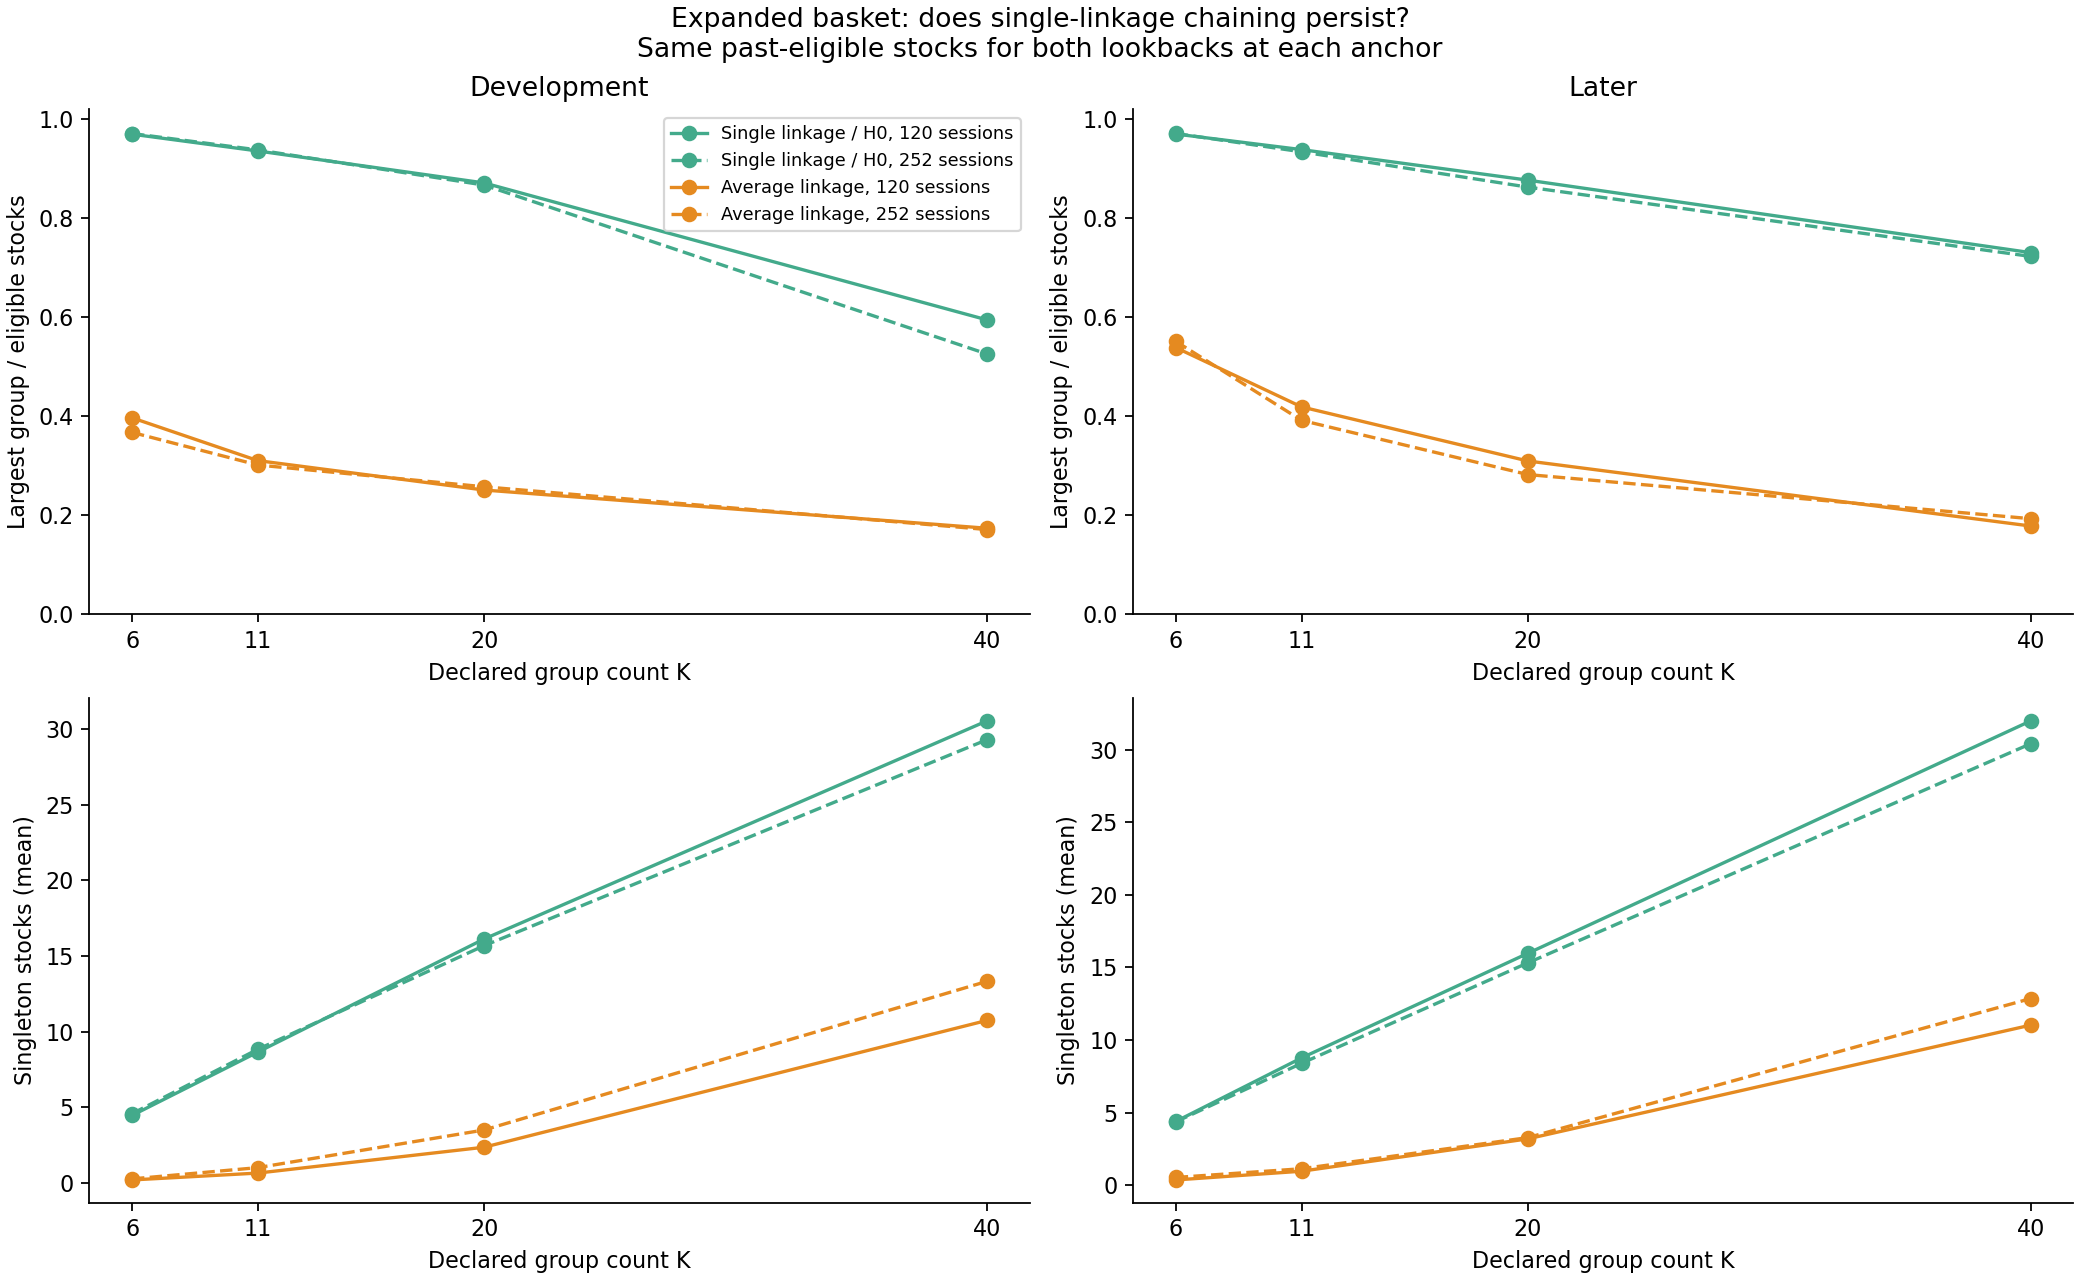

,window,method,groups,mean_stocks,mean_largest_group,mean_singleton_stocks
16,120,Single_H0,6,198.714,192.771,4.400
17,120,Single_H0,11,198.714,186.514,8.771
18,120,Single_H0,20,198.714,174.257,15.971
19,120,Single_H0,40,198.714,145.143,31.971
20,252,Single_H0,6,198.714,193.000,4.371
21,252,Single_H0,11,198.714,185.629,8.400
22,252,Single_H0,20,198.714,171.457,15.314
23,252,Single_H0,40,198.714,143.629,30.400
24,120,Average,6,198.714,107.029,0.371
25,120,Average,11,198.714,83.229,0.971


In [2]:
display(Image(filename=str(out / "01_group_balance.png")))
display(summary.loc[summary.period.eq("later"), ["window", "method", "groups", "mean_stocks", "mean_largest_group", "mean_singleton_stocks"]].round(3))

## 2. Longer histories improve measured resampling agreement

Forty five-session-block resamples perturb the prior data, with stocks and SPY sampled together and the SPY regression refitted. ARI measures partition agreement independent of arbitrary label numbers.

At eleven groups later, mean ARI rises from **0.468 to 0.536** for H0 and **0.527 to 0.601** for average linkage when moving from 120 to 252 observations. This is a sensitivity result, not a significance level or proof that 252 is optimal. Average linkage does not win every stability cell: H0 is slightly higher at later K=20 under both windows.

The short SPY-residual history has rank **118**, while long histories have rank **182–200**. Distances can be computed without inverting a covariance matrix. Singularity is not itself an invalid-distance error, but the small history relative to stock count motivates the declared window comparison. No shrinkage parameter was selected using future outcomes.

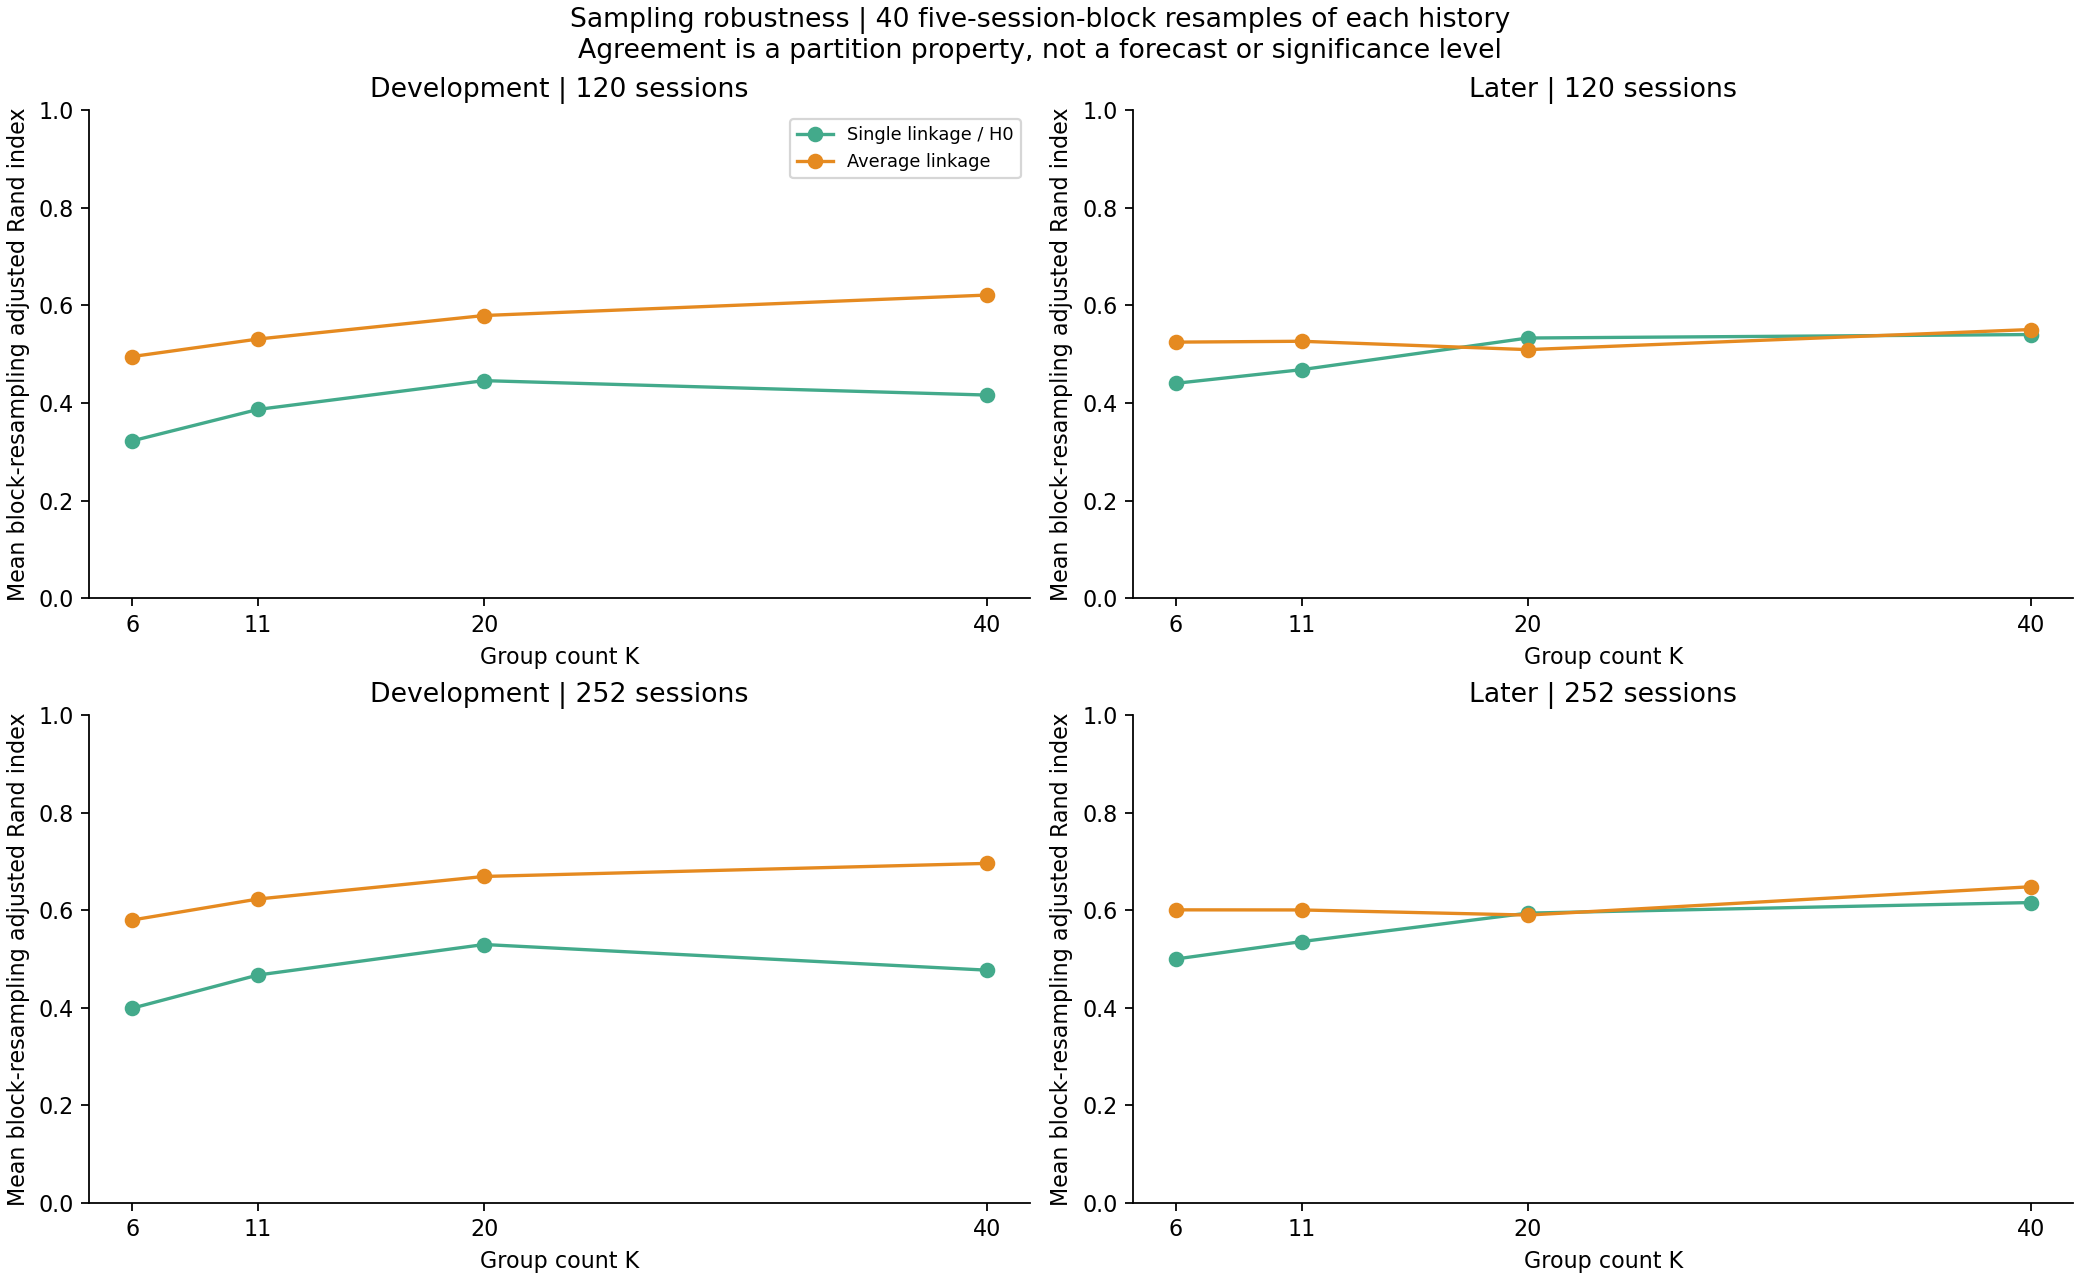

,period,window,method,mean_bootstrap_ARI,mean_shorter_ARI,mean_longer_ARI,mean_older_ARI
1,development,120,Single_H0,0.3867,0.6153,0.6493,0.7474
5,development,252,Single_H0,0.4672,0.7893,0.8035,0.8553
9,development,120,Average,0.5310,0.6684,0.6976,0.7343
13,development,252,Average,0.6230,0.8158,0.8073,0.8369
17,later,120,Single_H0,0.4683,0.6810,0.7215,0.7825
21,later,252,Single_H0,0.5357,0.8360,0.8129,0.8736
25,later,120,Average,0.5265,0.6624,0.7052,0.7452
29,later,252,Average,0.6006,0.7640,0.7568,0.8303


In [3]:
display(Image(filename=str(out / "02_partition_stability.png")))
display(summary.loc[summary.groups.eq(11), ["period", "window", "method", "mean_bootstrap_ARI", "mean_shorter_ARI", "mean_longer_ARI", "mean_older_ARI"]].round(4))

## 3. Do the groups remain more alike afterward?

For groups formed from past data, measure the next twenty sessions' average **within-group correlation minus between-group correlation**. Higher means better future separation on this metric. It does not measure price-spread equilibrium or subsequent reversal.

All methods, including both geometry windows, use **one common future target** based on the frozen prior 252-session SPY fit. Thus changing the geometry window does not change the future market benchmark.

At matched eleven groups later, the gap is about **0.063 for 252-session H0**, **0.210 for 252-session average linkage**, and **0.145 for provider sectors**. Average-minus-sector is +0.065, approximate simultaneous interval [+0.038,+0.091]. Group sizes and the pairs assigned within groups still differ: a better gap is not proof of better economic classifications or a better hedge.

Methods have approximate simultaneous intervals across eight (window,K) cells within each method/period. The single sector interval is pointwise. Shading near zero is a group-size-preserving random-label reference. All 32 mean method scores exceed the corresponding random upper reference; 31 method lower uncertainty bounds do too. The exception is development H0 with 252 sessions and K=6. More within-group coherence at finer K does not imply an optimal cut, because the within-pair coverage changes.

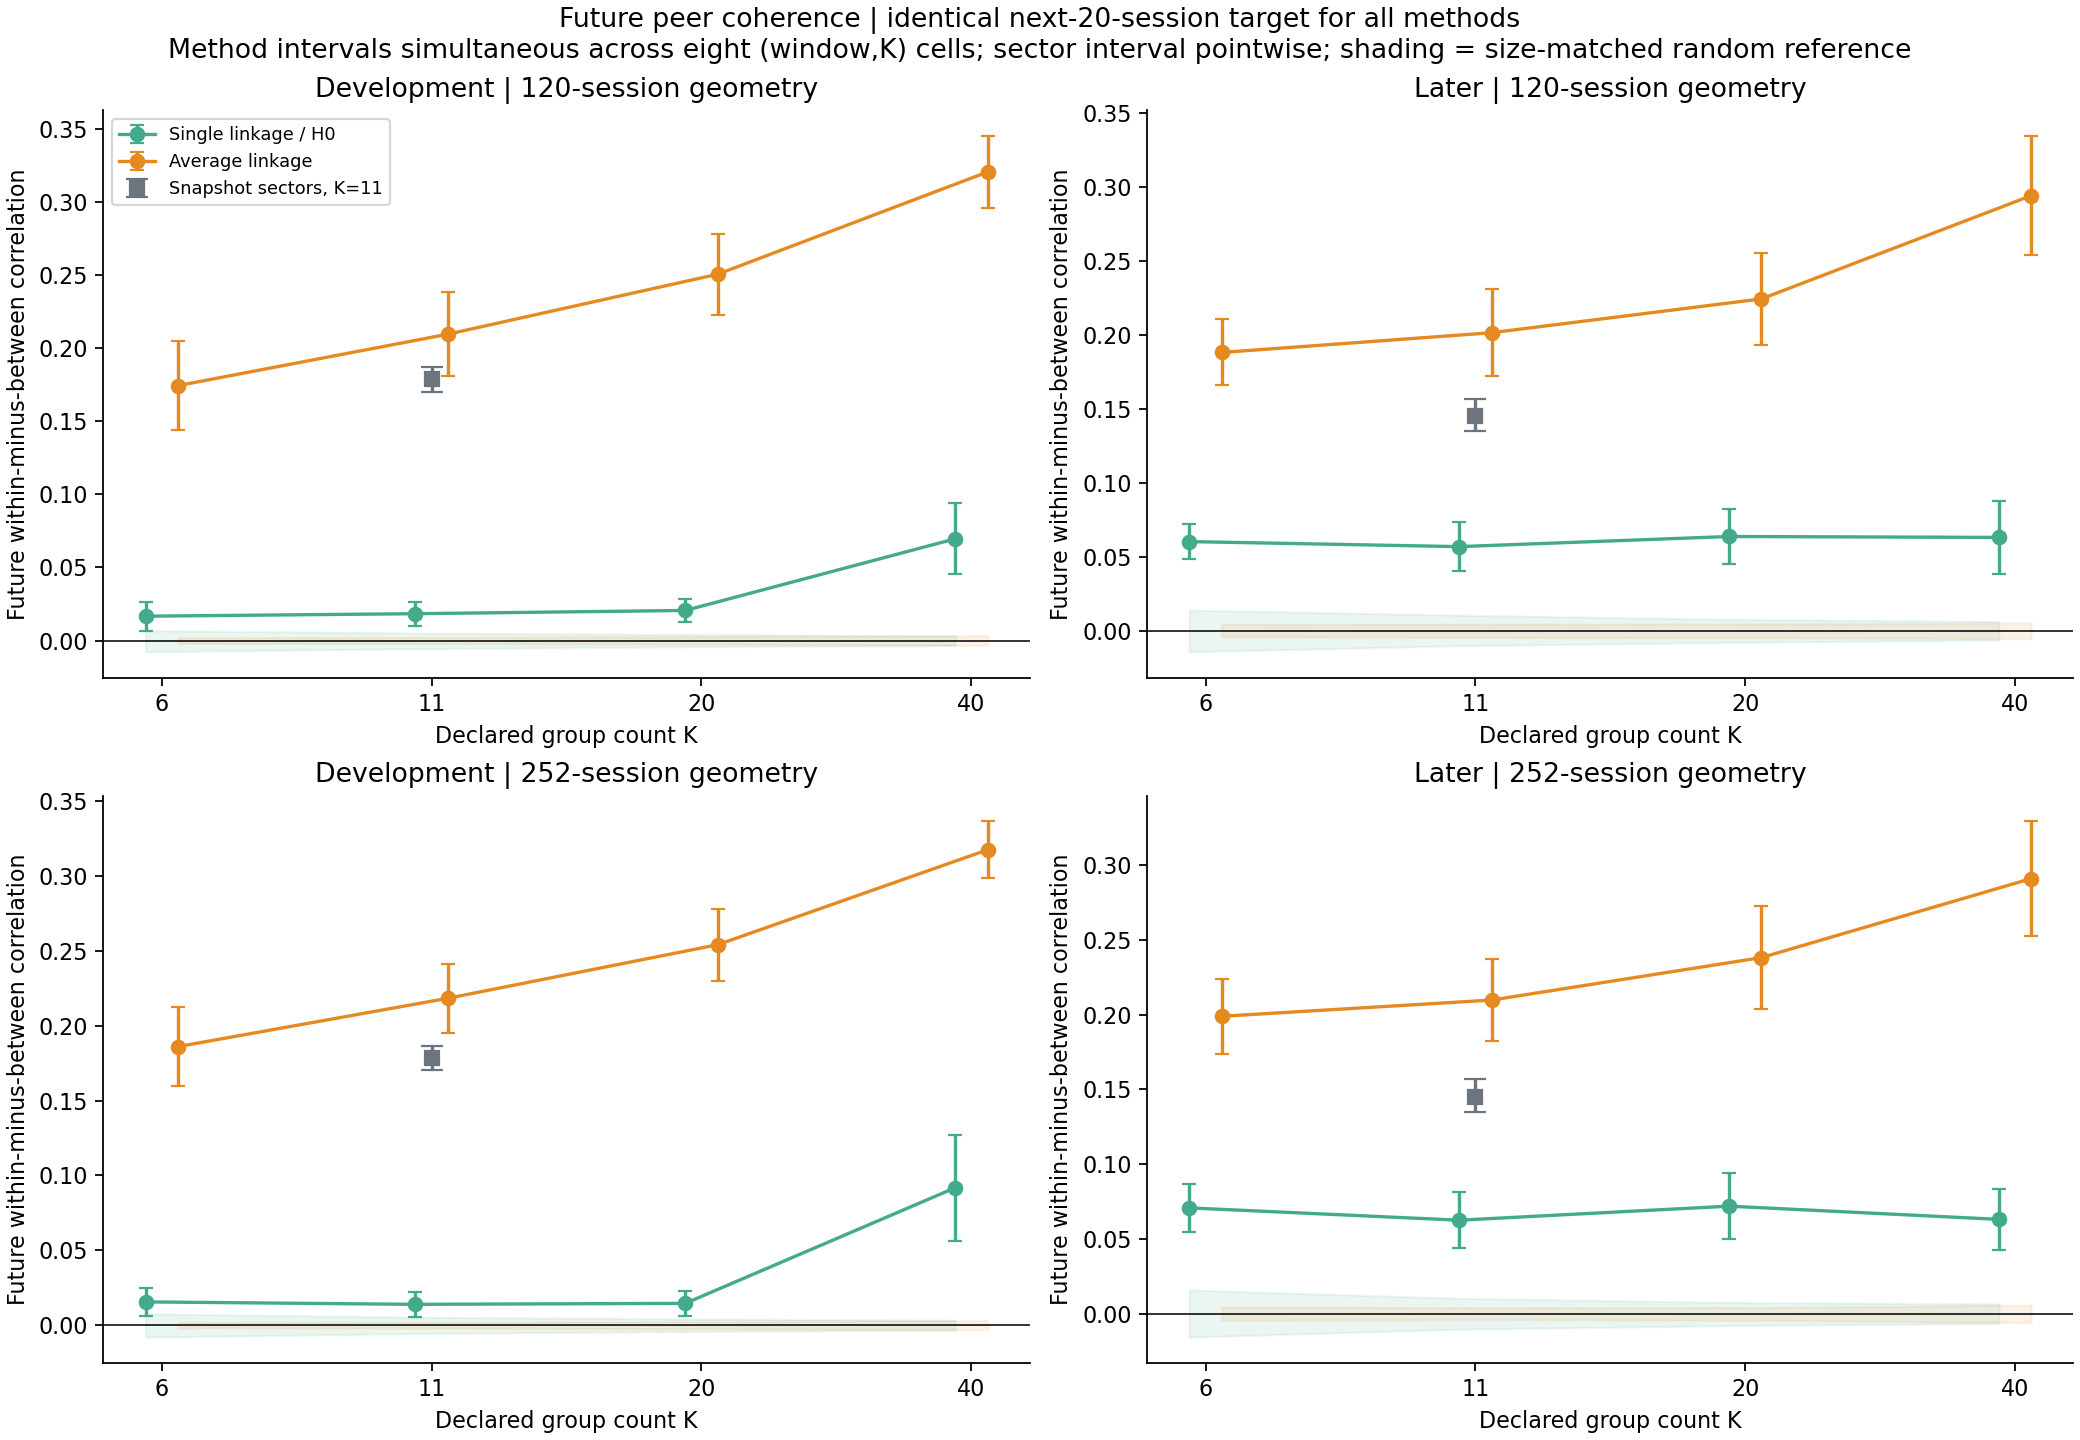

,window,method,future_gap_mean,sim95_low,sim95_high,method_minus_sector_gap,sector_diff_sim95_low,sector_diff_sim95_high
17,120,Single_H0,0.0569,0.0403,0.0734,-0.0883,-0.1108,-0.0657
21,252,Single_H0,0.0625,0.0438,0.0813,-0.0826,-0.1035,-0.0617
25,120,Average,0.2016,0.1721,0.2310,0.0564,0.0315,0.0813
29,252,Average,0.2098,0.1822,0.2374,0.0646,0.0381,0.0912


,period,anchors,future_gap_mean,point95_low,point95_high
0,development,86,0.1787,0.1702,0.1867
1,later,35,0.1452,0.1348,0.1570


In [4]:
display(Image(filename=str(out / "03_future_coherence.png")))
display(summary.loc[summary.period.eq("later") & summary.groups.eq(11), ["window", "method", "future_gap_mean", "sim95_low", "sim95_high", "method_minus_sector_gap", "sector_diff_sim95_low", "sector_diff_sim95_high"]].round(4))
display(sector.round(4))

## 4. Does H0 add anything over ordinary average linkage here?

Every paired H0-minus-average gap is negative, with its approximate simultaneous 95% interval below zero: all eight declared cells in development and all eight later. The later 252-session eleven-group difference is **-0.147**, interval **[-0.172,-0.122]**.

This supports average linkage for this measured structural task. It is not a rejection of all topological methods, all representations, or every possible single-linkage branch. The intervals cover the eight fixed cells within each period, not every past research decision or an untouched evaluation.

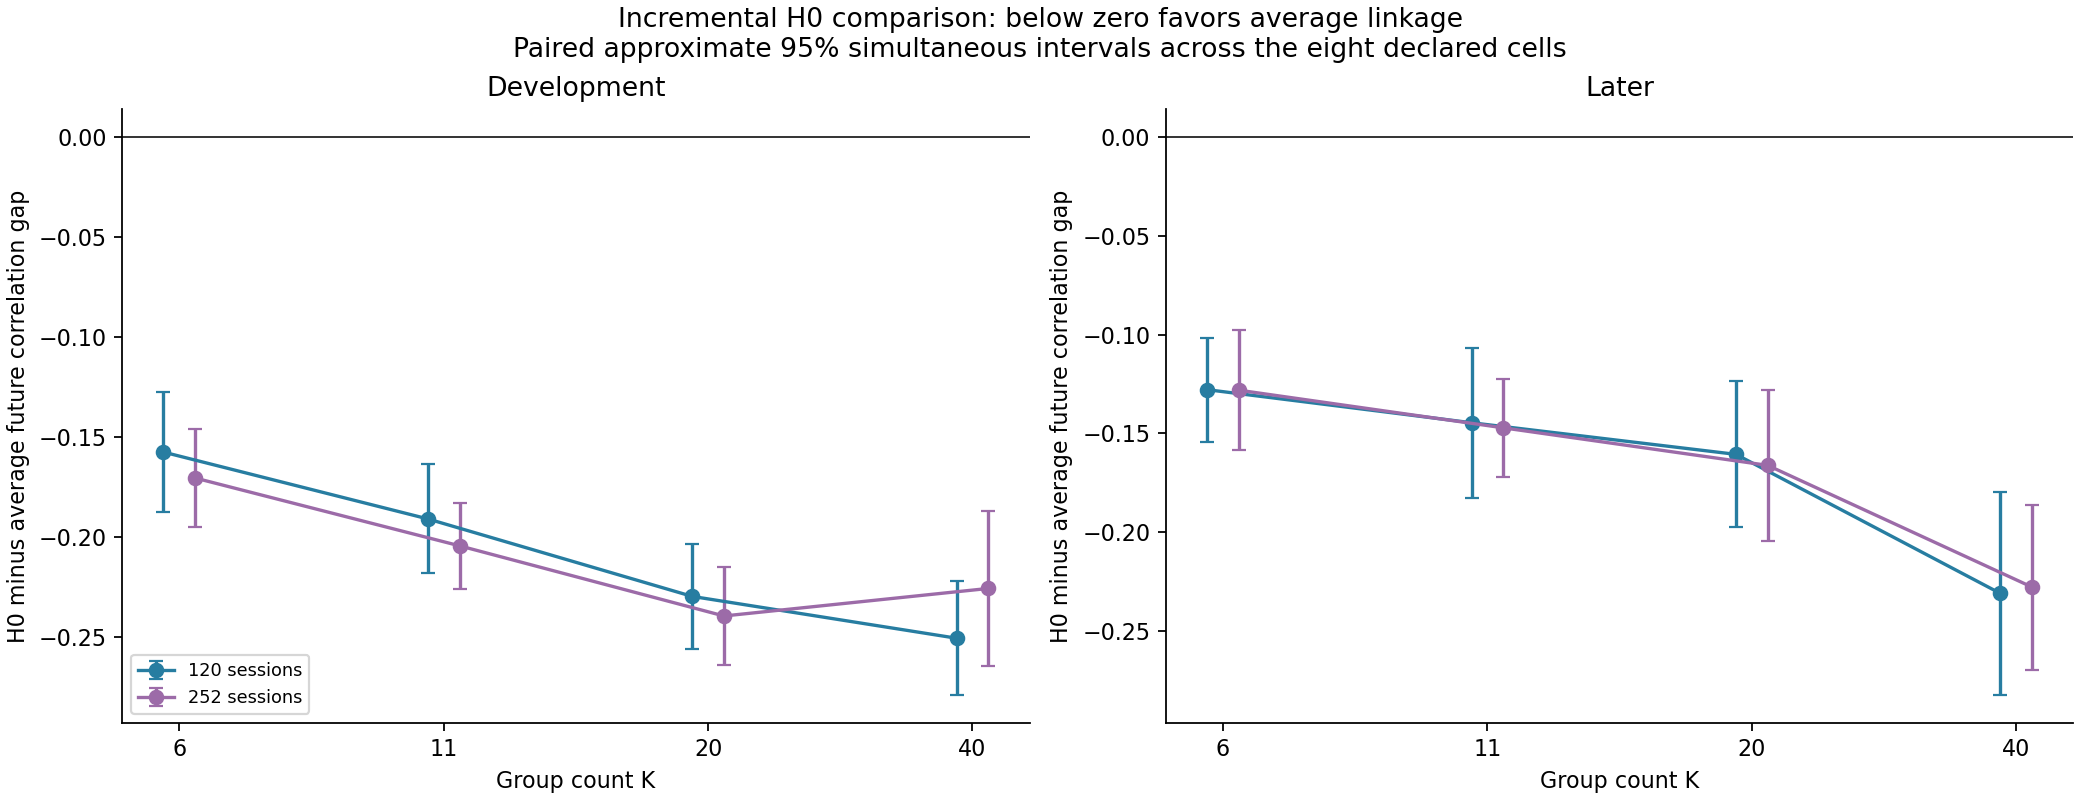

,period,window,groups,H0_minus_average_gap,point95_low,point95_high,sim95_low,sim95_high
0,development,120,6,-0.1576,-0.1829,-0.1353,-0.1877,-0.1275
1,development,120,11,-0.1911,-0.2131,-0.1701,-0.2183,-0.1638
2,development,120,20,-0.2299,-0.2507,-0.2078,-0.2563,-0.2034
3,development,120,40,-0.2508,-0.2735,-0.2296,-0.2792,-0.2224
4,development,252,6,-0.1706,-0.1911,-0.1519,-0.1952,-0.1459
5,development,252,11,-0.2045,-0.2210,-0.1861,-0.2260,-0.1831
6,development,252,20,-0.2397,-0.2593,-0.2198,-0.2643,-0.2150
7,development,252,40,-0.2259,-0.2565,-0.1960,-0.2646,-0.1871
8,later,120,6,-0.1279,-0.1534,-0.1072,-0.1543,-0.1016
9,later,120,11,-0.1447,-0.1787,-0.1143,-0.1828,-0.1066


In [5]:
display(Image(filename=str(out / "04_paired_method_differences.png")))
display(paired.round(4))
assert (paired.sim95_high < 0).all()

## 5. The positive finding: repeatable small peer branches

Poor global cuts do not mean there are no local relationships. Keep an exact **3–8-stock branch** when at least 30/40 history resamples and 2/3 window perturbations recover it anywhere in the tree. This is a past-only diagnostic, not a selected trading rule.

Later 252-session examples include **AEP/DUK/SO**, **AMAT/KLAC/LRCX**, **COP/CVX/EOG/XOM**, and **MPC/PSX/VLO**: each meets the diagnostic at all 35 later anchors. These named co-movement sets do not identify economic causes.

Of **496** stable H0 branch occurrences in the later 252-session fit, **486** also appear in average-linkage trees and **436** are stable under both. There are a few H0-only occurrences, so overlap is near-complete rather than exact. Average has about **18.1** stable local branches per later anchor, versus H0's **14.2**. Branches can nest and repeat; these are not independent discoveries. The size rule omits pairs and groups larger than eight, which may also have meaningful relationships.

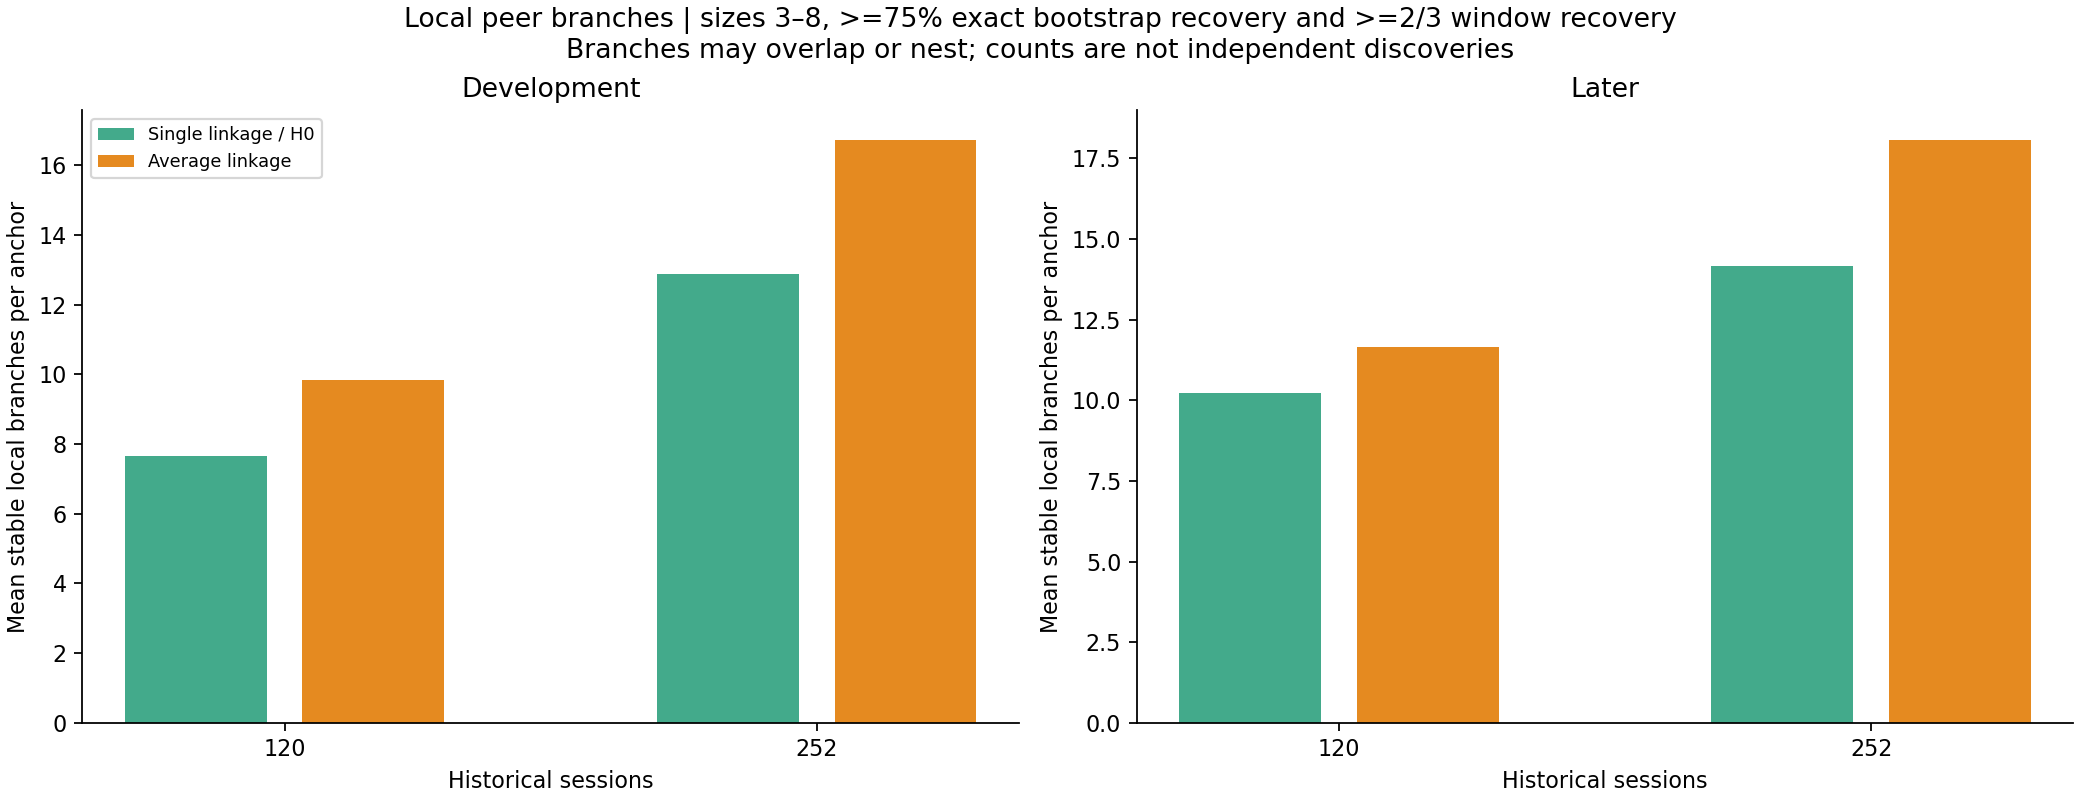

stable_H0_occurrences  ...  also_stable_in_average
period      window                         ...                        
development 120                       658  ...                     601
            252                      1107  ...                     991
later       120                       358  ...                     327
            252                       496  ...                     436

[4 rows x 3 columns]

,period,window,method,stocks,size,observed_anchors,stable_candidate_anchors,mean_bootstrap_recovery,mean_window_recovery,mean_future_local_gap
8931,later,252,Single_H0,AEP|DUK|SO,3,35,35,0.9907,1.0000,0.6990
8951,later,252,Single_H0,AMAT|KLAC|LRCX,3,35,35,1.0000,1.0000,0.8948
9127,later,252,Single_H0,COP|CVX|EOG|XOM,4,35,35,0.9736,1.0000,0.7284
9213,later,252,Single_H0,MPC|PSX|VLO,3,35,35,1.0000,1.0000,0.7959
8914,later,252,Single_H0,ADI|NXPI|TXN,3,35,33,0.9429,1.0000,0.6917
9165,later,252,Single_H0,CSX|NSC|UNP,3,35,31,0.9171,1.0000,0.6079
8940,later,252,Single_H0,AJG|AON|MRSH,3,35,24,0.8357,0.9619,0.6121
9216,later,252,Single_H0,PNC|TFC|USB,3,30,22,0.8317,0.9556,0.6675
8943,later,252,Single_H0,ALL|CB|PGR|TRV,4,33,21,0.7750,1.0000,0.5292
9208,later,252,Single_H0,KMI|OKE|TRGP|WMB,4,29,18,0.8362,0.9540,0.6251


stable_local_branches  stocks_in_stable_branch_union
period      window method                                                         
development 120    Average                    9.826                         30.419
                   Single_H0                  7.651                         23.849
            252    Average                   16.733                         51.058
                   Single_H0                 12.872                         39.733
later       120    Average                   11.657                         35.400
                   Single_H0                 10.229                         30.286
            252    Average                   18.086                         52.771
                   Single_H0                 14.171                         40.543

In [6]:
display(Image(filename=str(out / "05_stable_local_branches.png")))
display(overlap.groupby(["period", "window"])[["stable_H0_occurrences", "also_in_average", "also_stable_in_average"]].sum())
examples = catalogue.loc[catalogue.period.eq("later") & catalogue.window.eq(252) & catalogue.method.eq("Single_H0")]
display(examples.sort_values(["stable_candidate_anchors", "observed_anchors"], ascending=False).head(12).round(4))
display(counts.groupby(["period", "window", "method"])[["stable_local_branches", "stocks_in_stable_branch_union"]].mean().round(3))

## 6. What was fixed, and what remains uncertain

Admission uses 272 contiguous prior observations ending before the formation anchor, with no future-member filtering. Histories are never filled. Both fits and all comparisons use the same eligible stocks, keeping all original 30 at every anchor. The target begins the day after the formation anchor and has twenty observations. Target blocks do not overlap; blocks crossing January 2024 are omitted.

Window perturbations are 100/140 or 232/272 sessions, plus a five-session-older same-length history. Random controls use 250 common stock relabelings per anchor, preserving complete group-size patterns. Uncertainty uses 1,000 circular resamples of six consecutive anchors. The long fitting windows overlap, the six-anchor block is a modeling choice, and only 35 later target blocks exist: inference remains approximate.

The stock universe and sector labels are 2026 snapshots. Past-only admission does not remove survivor/size selection or make classifications historical. Share classes are not independent companies. Changing dates and eligibility also means this is not a controlled estimate of the causal effect of adding stocks alone.

No new strategy positions or returns are computed. These correlation results do not change the earlier unresolved mean-reversion finding, establish a random walk, or test multi-year valuation mean reversion.

In [7]:
for name, passed in audit["checks"].items():
    print(name, passed)
print("Maximum independently reconstructed gap error:", audit["max_independent_gap_error"])
assert all(audit["checks"].values())
assert all(result["checks"].values())

all_anchor_memberships_use_only_prior_272_returns True
formation_and_target_chronology_and_nonoverlap True
original_30_present_at_every_anchor True
all_cut_balance_endpoints_and_monotonicity True
all_nonroot_branches_recorded True
branch_threshold_flags_counts_unions_and_overlap_reproduce True
eleven_sampled_anchors_reconstructed_with_independent_distance_and_clustering True
single_linkage_cuts_equal_threshold_connected_components True
common_future_target_and_sector_scores_reproduce True
first_anchor_all_250_size_matched_random_scores_reproduced True
first_anchor_all_history_and_window_perturbation_ARIs_and_branch_recoveries_reproduced True
summary_and_paired_means_and_null_cell_ordering_reproduce True
all_method_sector_and_paired_pointwise_and_simultaneous_bootstrap_intervals_reproduced True
protected_inputs_and_prior_experiments_unchanged True
Maximum independently reconstructed gap error: 1.1171619185290638e-14


## Research decision

Keep **average linkage as the stronger tested structural baseline**, with sectors and labeled local branches as useful references. The positive insight is persistent peer structure extending beyond coarse sector labels under this metric. The negative incremental result is that a fixed-K H0 partition is not a better way to organize the broad basket here.

The longer window improves measured stability without fixing H0 chaining or establishing an optimal horizon. Robust H0 branches are mostly available through ordinary clustering. An additional trading rule, optimal-cut claim, or new TDA construction needs its own design; this study supplies no new return-reversal edge.

Reproduce in the equity directory with `OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python experiments/equity_expanded_structure.py`, then `python experiments/audit_equity_expanded_structure.py`. The original datasets, frozen source files, and prior result summaries are preserved.